# Regarder les poids de la première couche

Lance les cellules dans l'ordre (noyau : `.venv`).
**Entraîner** réaffiche les poids plusieurs fois par époque, pendant l'apprentissage.
Tu peux la relancer autant de fois que tu veux : l'entraînement reprend là où il s'était arrêté.

Pour repartir de zéro, relance **Créer le réseau**.

In [140]:
# 1. Chargement (une seule fois)
import sys, os, random
import numpy as np
sys.path.insert(0, os.path.abspath("../outils"))
from visu import charger_mnist, afficher_poids, entrainer_en_direct, comparer
import warnings; warnings.filterwarnings("ignore", category=SyntaxWarning)  # docstring de network.py
import network

training_data, validation_data, test_data = charger_mnist()
petit = training_data[:1000]   # sous-ensemble fixe de 1 000 images
essais = []                    # pour comparer les essais

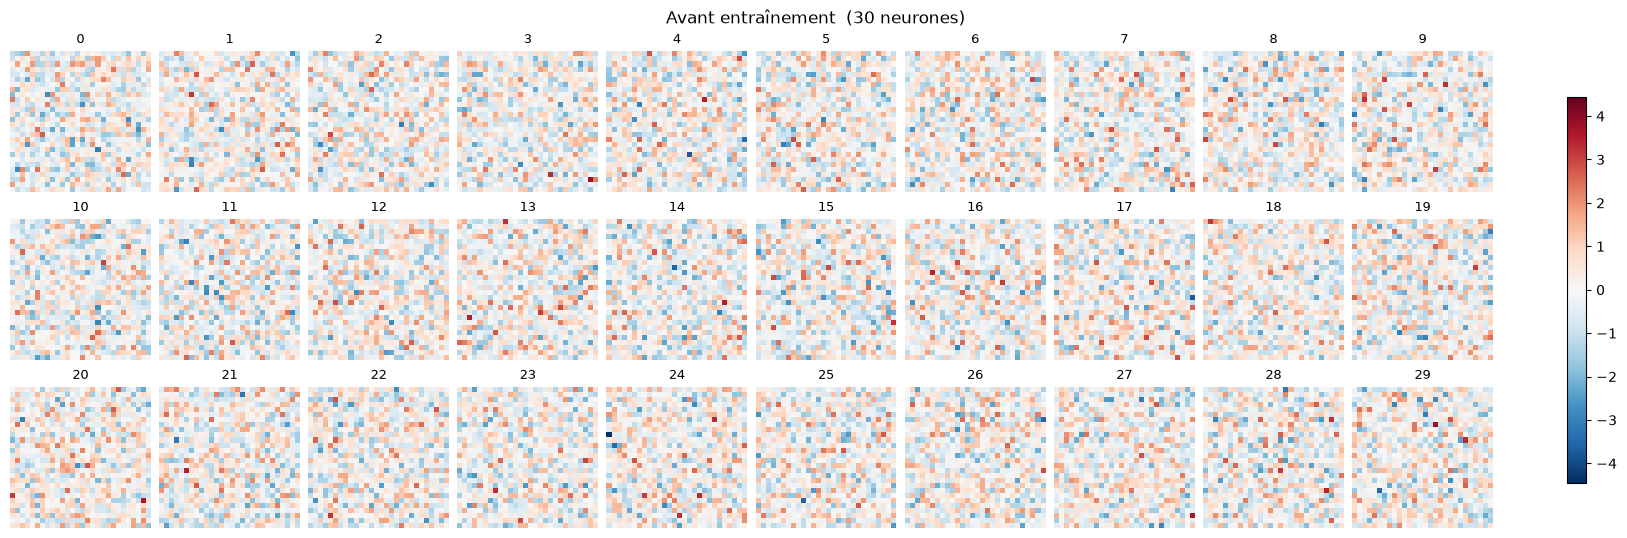

In [141]:
# 2. Créer le réseau
random.seed(0); np.random.seed(0)    # mêmes tirages à chaque fois
net = network.Network([784, 30, 10])     # <- change l'architecture ici
W0 = net.weights[0].copy()           # photo des poids avant entraînement
afficher_poids(net, titre="Avant entraînement")

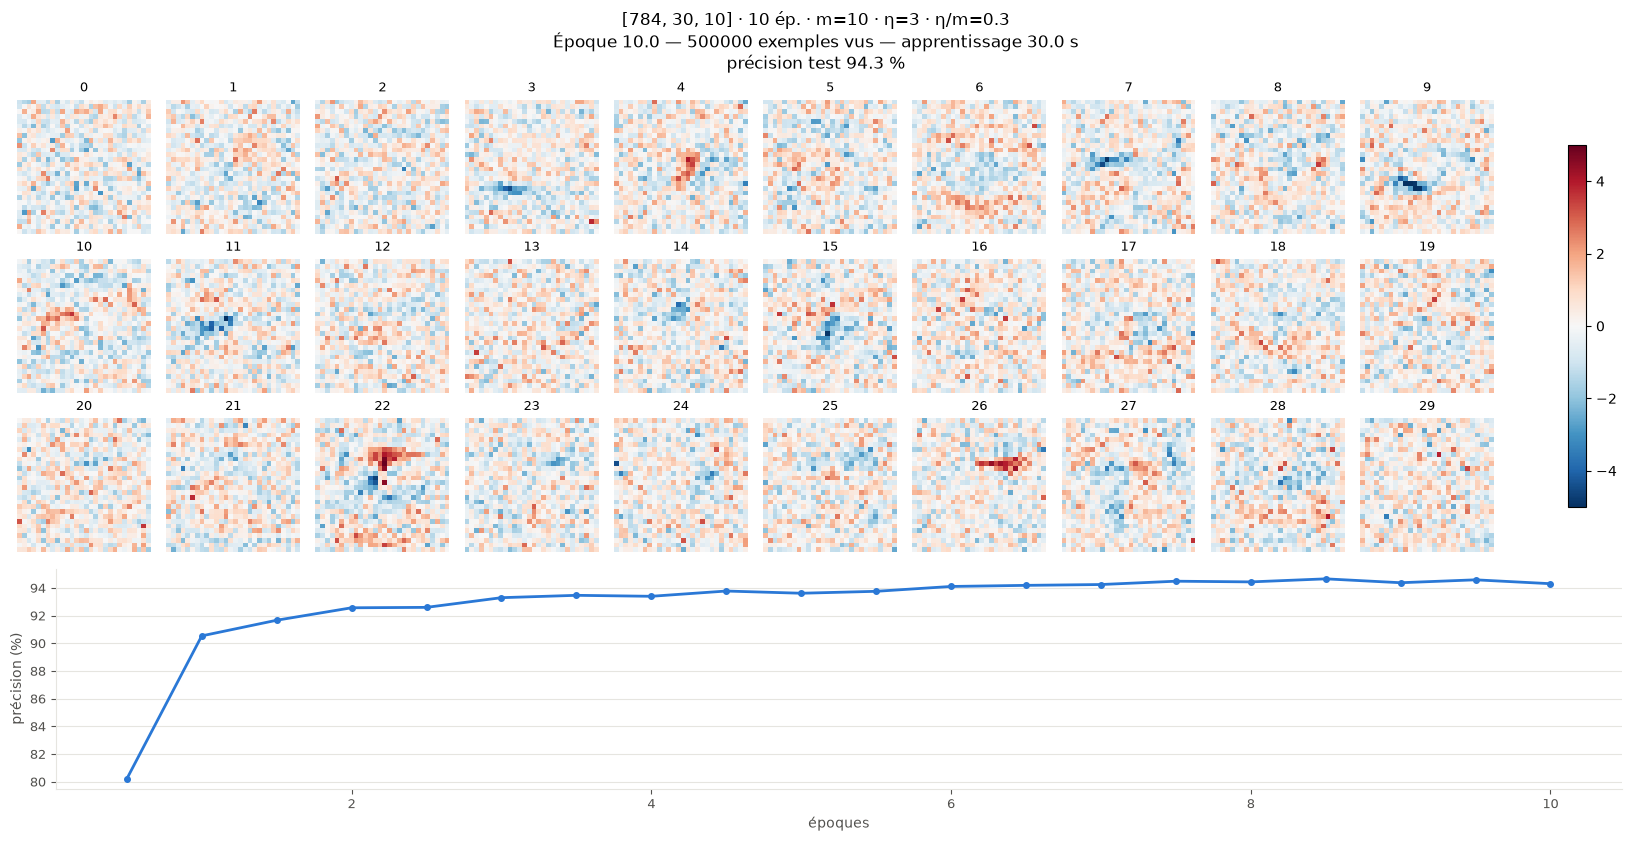

Temps d'apprentissage seul : 30.0 s   (mesure de la précision : 2.5 s, affichage : 19.7 s, total : 52.1 s)


In [142]:
# 3. Entraîner en regardant les poids évoluer
#    époques, taille du mini-batch, eta
#    images_par_epoque : nombre d'images affichées par époque
#    reference=W0 : ne montre que ce que l'entraînement a changé (None = poids bruts)
#    echelle=3    : fige la barre de couleurs à ±3 (None = automatique)
historique = entrainer_en_direct(net, training_data, 10, 10, 3, test_data=test_data,
                                 images_par_epoque=2, reference=None, echelle=5)

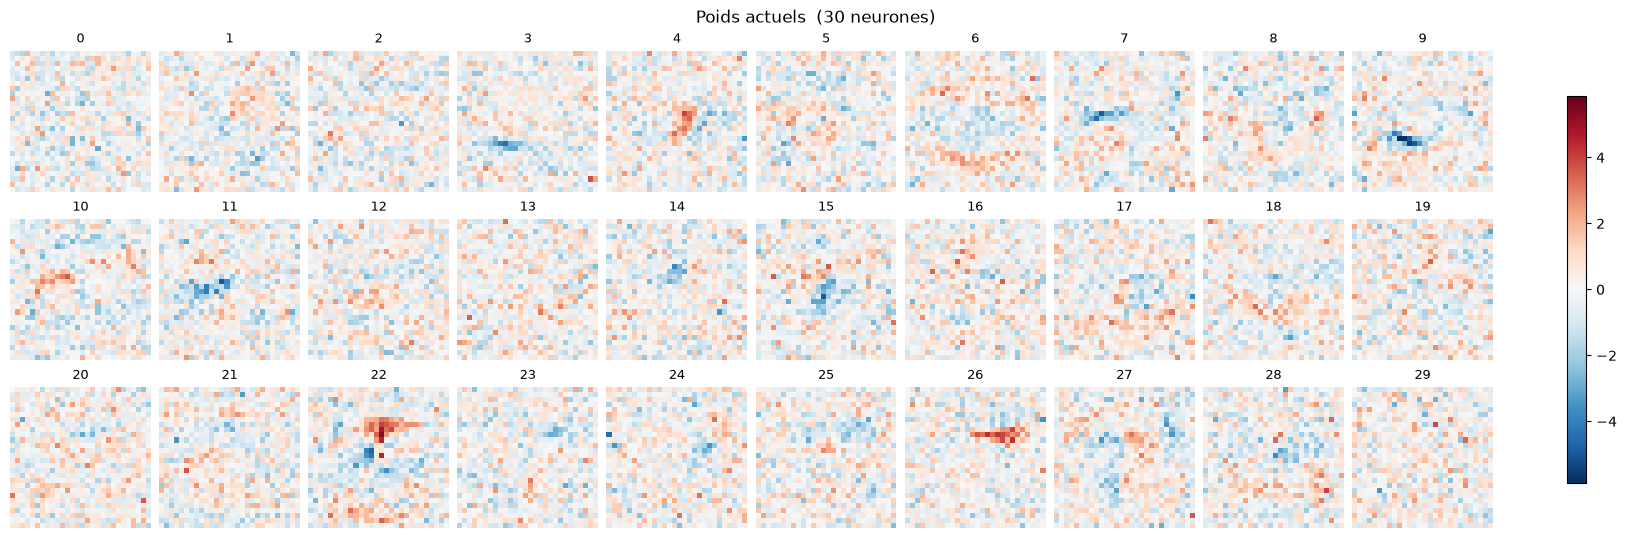

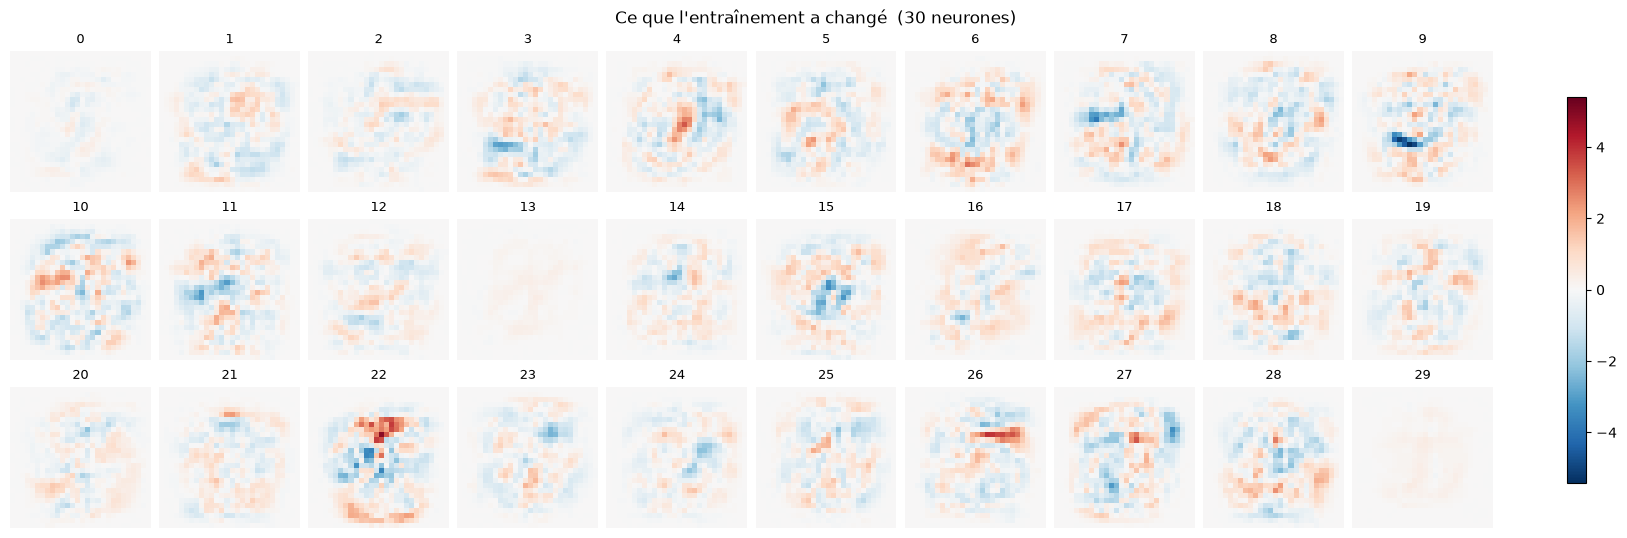

In [143]:
# 4. Regarder
afficher_poids(net, titre="Poids actuels")
afficher_poids(net, reference=W0, titre="Ce que l'entraînement a changé")

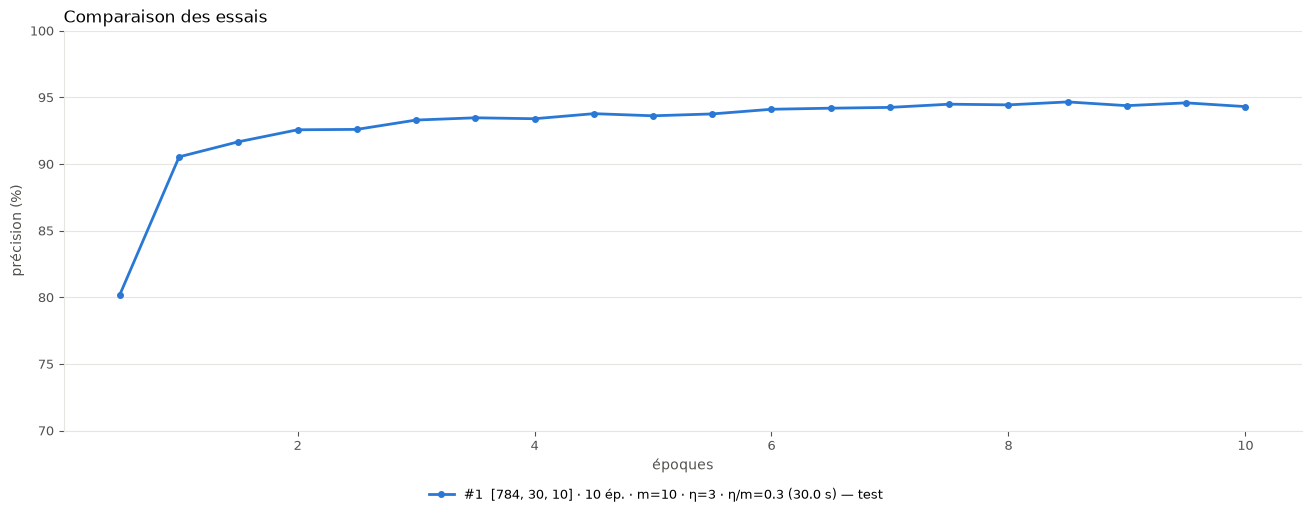

In [144]:
# 5. Comparer les essais
essais.append(historique)
comparer(essais)

In [145]:
import importlib, visu
importlib.reload(visu)    # charge la nouvelle version de visu.py ; essais est conservé
visu.exporter(essais)
visu.comparer(essais,filtre="[784,30]")

1 essais enregistrés :
  c:\AItools\Projets\Neural-Networks\experiences\resultats\essais.csv
  c:\AItools\Projets\Neural-Networks\experiences\resultats\essais.json
Aucun essai ne correspond au filtre.
